# What a crusher breaks and what comes out: the t10 energy curve, the appearance function and the classification curve

**Question:** How does the energy applied to a rock set the fineness of its fragments, and which sizes does a cone crusher choose to break at a given setting?

- **Level:** 1, Fundamentals
- **Prerequisites:** notebooks 01 and 02 of topic 02-size-distributions
- **Reading time:** about 30 minutes

## Objectives

By the end of this notebook you can:

- compute the specific energy a nip applies and turn it into the fineness index t10 of the JKMRC drop-weight test;
- draw the appearance function that says how a broken particle's mass is shared among finer sizes, and read the t-family from it;
- draw the classification curve that says which sizes a nip takes and which pass through;
- say how the machine's setting and the ore's competence move each curve.

## Setup

Numpy and matplotlib, as everywhere in the set.

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

The cell imports the engine's breakage and classification modules directly, one function per idea of this notebook, and the table of design throws per machine.

In [1]:
# Print the versions of the tools this notebook uses, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# The notebook sits three folders below the repository root; the pipeline is imported by its path
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher.breakage import specific_energy, t10_of, phi_from_t10, appearance_cum, t_family
from pipeline.model.crusher.classification import classification_params, classify
from pipeline.model.crusher.machines import REF_THROW_MM
from pipeline.model.crusher import Operating, evaluate
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Data

The operating point of the reference case S01 (a secondary cone, CSS 32 mm, 360 rpm, ore A*b = 55). Owner: this repository, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Licence class: MIT; the committed artifacts are written by the pipeline from the parameters of each case. File read: `data/derived/manifests/S01.json`, block `params`.

The cell reads the operating point and the feed F80 that the engine computes for it.

In [2]:
# Read the S01 operating point and the F80 the engine computes for its feed
op = Operating(**json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))["params"])
f80 = evaluate(op).f80
print(op.machine, "CSS", op.css_mm, "mm,", op.speed_rpm, "rpm, A*b", op.ore_axb, "| F80", round(f80, 2), "mm")

cone-sec CSS 32.0 mm, 360.0 rpm, A*b 55.0 | F80 126.03 mm


## Method

**Step 1, the energy of a nip.** A crusher breaks rock by squeezing it. The engine summarises the squeeze as a specific comminution energy per nip, in kWh per tonne, that grows with the machine's design throw and with its speed: $E_{cs} = 0.033\,T_{ref}\,(\mathrm{rpm}/350)$, where $T_{ref}$ is the design throw of the machine type (30 mm for a secondary cone). The live throw slider does not enter here: more throw coarsens the product through the classification, not through the energy. The cell evaluates the energy of S01 and of every machine type at its own design point.

In [3]:
# Specific energy per nip for S01, and for each machine type at a speed of 350 rpm
ecs = specific_energy(op.speed_rpm, REF_THROW_MM[op.machine])
print(f"S01: Ecs = {ecs:.4f} kWh/t")
for machine, throw in REF_THROW_MM.items():
    print(f"{machine:16s} design throw {throw:3d} mm -> Ecs = {specific_energy(350, throw):.3f} kWh/t")

S01: Ecs = 1.0183 kWh/t
cone-sec         design throw  30 mm -> Ecs = 0.990 kWh/t
cone-tert        design throw  16 mm -> Ecs = 0.528 kWh/t
cone-short-head  design throw  16 mm -> Ecs = 0.528 kWh/t
gyratory         design throw  30 mm -> Ecs = 0.990 kWh/t
jaw              design throw  38 mm -> Ecs = 1.254 kWh/t


**Step 2, from energy to fineness.** The JKMRC drop-weight test measures how finely a rock breaks for a given energy, with the index $t_{10}$, the fraction of the fragments finer than a tenth of the parent size. Its energy-fineness relation is $t_{10} = A\,(1 - e^{-b E_{cs}})$ (Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193), where $A$ is the limiting fineness and $b$ the rate at which the ore approaches it. Only the product $A b$ matters for ranking ores: a low value is a hard ore. The engine fixes $A = 60$ percent, caps $t_{10}$ at 0.44 so that the appearance function below can represent it, and reads $b = A b / A$. The figure draws $t_{10}$ against the energy for a hard (A*b = 30), a medium (55, S01's) and a soft (110) ore and marks S01's operating point.

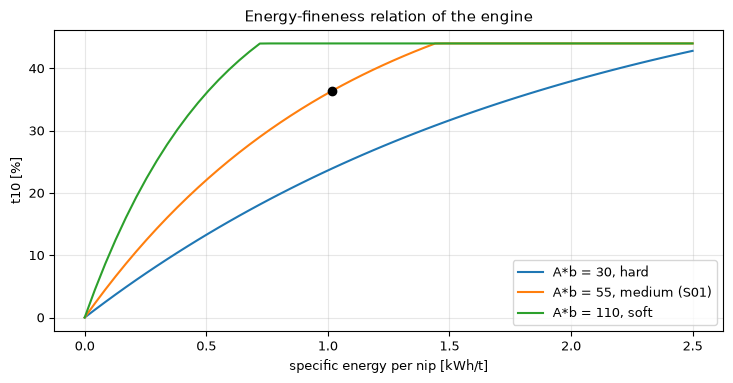

t10 of S01 = 0.3641


In [4]:
# Plot t10 against the specific energy for a hard, a medium and a soft ore and mark S01
energy = np.linspace(0, 2.5, 60)
fig, ax = plt.subplots()
for axb, name in ((30, "hard"), (55, "medium (S01)"), (110, "soft")):
    ax.plot(energy, [t10_of(e, axb) * 100 for e in energy], label=f"A*b = {axb}, {name}")
ax.plot([ecs], [t10_of(ecs, op.ore_axb) * 100], "ko")
ax.set_xlabel("specific energy per nip [kWh/t]")
ax.set_ylabel("t10 [%]")
ax.set_title("Energy-fineness relation of the engine")
ax.legend()
fig.tight_layout()
plt.show()
print(f"t10 of S01 = {t10_of(ecs, op.ore_axb):.4f}")

The curves rise steeply and then flatten, since each extra unit of energy buys less fineness, and they flatten at the 44 percent cap, which the soft ore reaches before 1 kWh/t. S01's point sits on the medium curve at t10 = 36.4 percent. The figure does not show the shape of the fragment sizes, only the one number t10; the next step turns that number into a whole distribution.

**Step 3, the appearance function.** For a parent of size $y$ the cumulative share of fragments finer than $x$ follows the Austin shape, with $u = x/y$:

$$B(u) = \varphi\,u^{\gamma} + (1 - \varphi)\,u^{\beta}, \qquad \gamma = 0.35,\ \beta = 4.2$$

(Austin, Klimpel and Luckie, 1984, as the engine's module cites them; the product's source for the family is Napier-Munn et al., 1996). The weight $\varphi$ is solved so that the curve passes through $t_{10}$ at $u = 1/10$. The JKMRC t-family, $t_n$ for the fraction finer than $y/n$, is read from the same curve. The cell solves $\varphi$ for the three ores at S01's energy and prints $t_2$ to $t_{75}$ of S01.

In [5]:
# Solve the appearance weight for the three ores at S01's energy and print the t-family of S01
phis = {axb: phi_from_t10(t10_of(ecs, axb)) for axb in (30, 55, 110)}
for axb, phi in phis.items():
    print(f"A*b = {axb:3d}: t10 = {t10_of(ecs, axb):.3f}, phi = {phi:.3f}")
for k, tn in t_family(t10_of(ecs, op.ore_axb)):
    print(f"t{k:<3d} = {tn:.3f}")

A*b =  30: t10 = 0.239, phi = 0.536
A*b =  55: t10 = 0.364, phi = 0.815
A*b = 110: t10 = 0.440, phi = 0.980
t2   = 0.650
t4   = 0.502
t10  = 0.364
t25  = 0.264
t50  = 0.207
t75  = 0.180


The figure draws the appearance function for the three ores on logarithmic axes, with S01's t-family as points. At $u = 0.1$ each curve passes through its $t_{10}$, and the three curves part company on both sides: the hard ore keeps more of its mass in coarse fragments (low on the left), the soft one makes more fines.

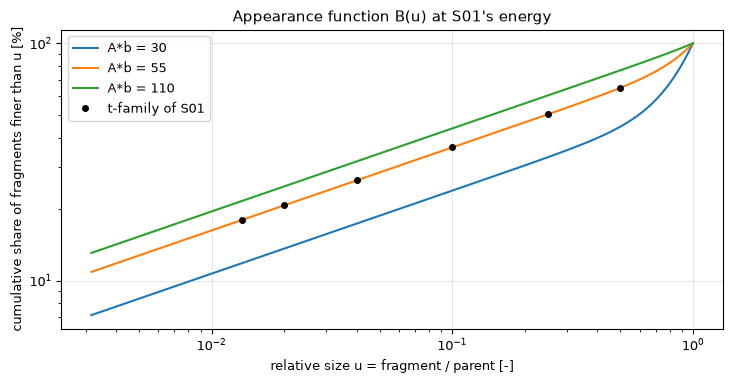

In [6]:
# Plot the cumulative appearance function for the three ores and the t-family of S01
u = np.logspace(-2.5, 0, 120)
fig, ax = plt.subplots()
for axb, phi in phis.items():
    ax.plot(u, [appearance_cum(v, phi) * 100 for v in u], label=f"A*b = {axb}")
family = t_family(t10_of(ecs, op.ore_axb))
ax.plot([1 / k for k, _ in family], [tn * 100 for _, tn in family], "ko", ms=4, label="t-family of S01")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("relative size u = fragment / parent [-]")
ax.set_ylabel("cumulative share of fragments finer than u [%]")
ax.set_title("Appearance function B(u) at S01's energy")
ax.legend()
fig.tight_layout()
plt.show()

The figure shows that one number, t10, fixes the whole shape: points of S01's family fall on its curve, so t2 and t75 need no further parameter. It does not show where the fragments go on the sieve grid, which is a matter of the parent's size; that bookkeeping is the breakage matrix of the next notebook. Next is the second ingredient, the classification.

**Step 4, the classification curve.** Not every particle that enters the chamber is nipped: the small ones fall through the gap, the large ones cannot. The classification function $C(d)$ is the probability that a particle of size $d$ is nipped and broken rather than passing through (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf), in the K1, K2, K3 form of Andersen and Napier-Munn (1988; https://www.semanticscholar.org/paper/Power-prediction-for-cone-crushers-Andersen-Napier-Munn/2c60e81b909b65cba85b44583354dc8e310ec2f8):

$$C(d) = \begin{cases} 0 & d \le K_1 \\ 1 - \left(\dfrac{K_2 - d}{K_2 - K_1}\right)^{K_3} & K_1 < d < K_2 \\ 1 & d \ge K_2 \end{cases}$$

$K_1$ grows with the closed-side setting, and $K_2$ follows the open-side setting, so a larger throw lets larger particles escape (Evertsson, 1999; https://doi.org/10.1016/S0892-6875(99)00136-3). The cell asks the engine for the three constants at S01's setting and at a tight and an open one.

In [7]:
# K1, K2, K3 for S01's setting, a 15 % tighter and a 15 % wider one
settings = {"tight": op.css_mm * 0.85, "S01": op.css_mm, "open": op.css_mm * 1.15}
constants = {name: classification_params(op.machine, css, f80_mm=f80, calibrated=False, throw_mm=op.throw_mm) for name, css in settings.items()}
for name, k in constants.items():
    print(f"{name:7s} CSS = {settings[name]:5.2f} mm  K1 = {k.k1:6.2f}  K2 = {k.k2:6.2f}  K3 = {k.k3}")

tight   CSS = 27.20 mm  K1 =  24.68  K2 =  59.04  K3 = 2.3
S01     CSS = 32.00 mm  K1 =  29.00  K2 =  68.40  K3 = 2.3
open    CSS = 36.80 mm  K1 =  33.32  K2 =  77.76  K3 = 2.3


The figure draws C(d) for the three settings on a logarithmic size axis.

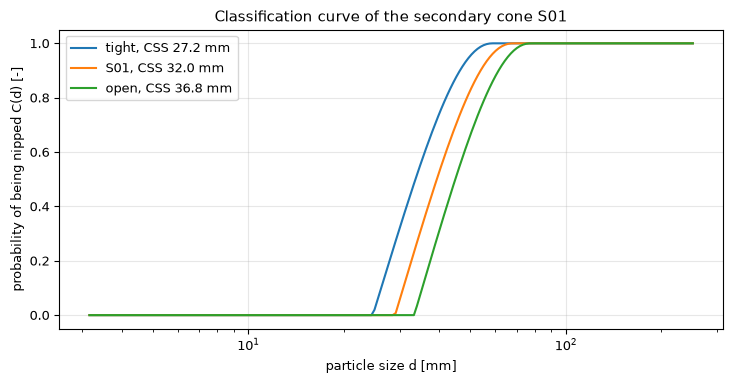

In [8]:
# Plot C(d) for the three settings against particle size
sizes = np.logspace(0.5, 2.4, 200)
fig, ax = plt.subplots()
for name, k in constants.items():
    ax.plot(sizes, [classify(d, k) for d in sizes], label=f"{name}, CSS {settings[name]:.1f} mm")
ax.set_xscale("log")
ax.set_xlabel("particle size d [mm]")
ax.set_ylabel("probability of being nipped C(d) [-]")
ax.set_title("Classification curve of the secondary cone S01")
ax.legend()
fig.tight_layout()
plt.show()

Each curve is zero up to its K1 and one from its K2, and the whole S-shape moves to the right as the setting opens: at S01's own setting particles below 29 mm are never nipped and those above 68.4 mm always are. Between those sizes the material is sorted by chance, which is why the product of a crusher always contains some oversize relative to the setting. The figure shows the selection, but not what the crusher does to a selected particle (that is the appearance function) nor how the product is assembled when fragments may be nipped again; that is the Whiten solve of the next notebook.

## Results

**Answer:** at S01 a nip applies 1.0183 kWh/t, which gives t10 = 0.3641 for the A*b = 55 ore and an appearance weight phi = 0.815, so t2 to t75 run from 0.650 to 0.180. A harder ore (A*b = 30) gets t10 = 0.239 at the same energy and a softer one (110) hits the 0.44 cap. For the setting, the crusher chooses its particles by size: K1 = 29.00 mm, K2 = 68.40 mm and K3 = 2.3 at the S01 setting of 32 mm, so particles under 29 mm pass without being broken and those over 68.4 mm are always nipped.

The first figure shows fineness saturating with energy, the second the one-parameter family of fragment sizes, the third the selection sliding to coarser sizes as the setting opens. A validator would conclude that the engine's breakage side is a chain of three published relations with few free numbers, and that the setting acts on selection while the ore acts on fragmentation: tightening the crusher selects smaller particles, a harder ore breaks into coarser fragments. None of the three curves yet says what the product looks like; that needs them combined, as in notebook 02.

## Summary

Energy per nip fixes the fineness index t10 through the ore's A*b, t10 fixes the appearance function, and the setting fixes which sizes are selected. These are the two ingredients of the crusher model: a selection function C and a breakage function B. Notebook 02 combines them into the population balance that Whiten wrote for a crusher and solves it step by step.

## References

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193
- Andersen, J. S., Napier-Munn, T. J. (1988), Power prediction for cone crushers, Proc. 3rd Mill Operators' Conference, AusIMM, 103-109. https://www.semanticscholar.org/paper/Power-prediction-for-cone-crushers-Andersen-Napier-Munn/2c60e81b909b65cba85b44583354dc8e310ec2f8
- Evertsson, C. M. (1999), Modelling of flow in cone crushers, Minerals Engineering 12(12), 1479-1499. https://doi.org/10.1016/S0892-6875(99)00136-3